In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
sys.path.append('../../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'

In [2]:
with open('../../Figure4/corr_harris.pkl', 'rb') as f:
    corr_harris = pickle.load(f)
with open('../../Figure4/corr_in_silico_complex.pkl', 'rb') as f:
    corr_in_silico_complex = pickle.load(f)

In [3]:
corr1 = corr_in_silico_complex
corr2 = corr_harris

r1 = np.array([x[0] for x in corr1], dtype=float)
p1 = np.array([x[1] for x in corr1], dtype=float)

r2 = np.array([x[0] for x in corr2], dtype=float)
p2 = np.array([x[1] for x in corr2], dtype=float)

mask = (p1 < 0.05) & (p2 < 0.05)
idx = np.where(mask)[0]

{'r': 0.45407219695324125, 'p': 0.05083142148759666, 'ci_low': -0.00017270976502232002, 'ci_high': 0.752983332981786, 'n': 19}


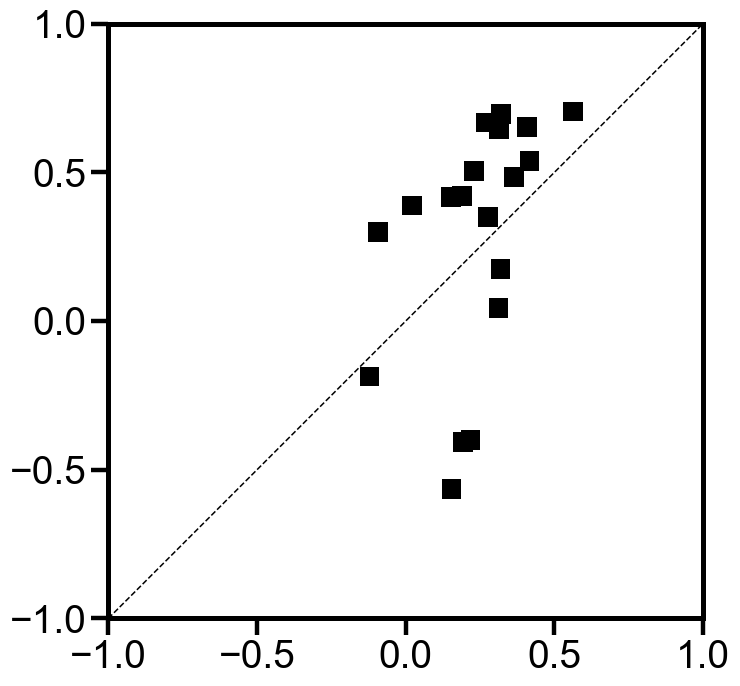

In [4]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(8, 8))


ax.scatter(
    r1[:19], r2[:19],
    s=200,
    color="black",
    edgecolors="none",
    marker='s'
)

ax.set_box_aspect(1)

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_yticks(np.arange(-1, 1.01, 0.5))
xmin, xmax = ax.get_xlim()
ax.plot([xmin, xmax], [xmin, xmax], linestyle="--", color="black", linewidth=1.1, alpha=1)

ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)


print(pearson_ci(r1, r2, confidence=0.95))
plt.tight_layout()
# fig.savefig("Supp_Figure7b.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()
